# Engenharia de Recursos (*Feature Engineering*) e Transformação
Com a base limpa e validada no notebook anterior (*02_eda_e_tratamento.ipynb*), entramos na etapa de Engenharia de Recursos. Trataremos os valores extremos (outliers) identificados, criar novas variáveis de interação comportamental e preparar o terreno para a modelagem preditiva.

---
Vamos estruturar o início do nosso notebook carregando a base tratada do SQLite e aplicando o tratamento de winsorization (corte de extremos) nas colunas de alta assimetria (`RevolvingUtilizationOfUnsecuredLines` e `DebtRatio`).

## Carregamento da Base e Tratamento de Extremos (*Winsorization*)

Nesta etapa, importamos a base tratada (`credito_tratado`) e aplicamos limites de corte estatístico (*clipping*) nas variáveis de utilização de crédito e endividamento. Isso blinda tanto os modelos lineares quanto as árvores contra ruídos extremos causados por distorções de cadastro ou limites zerados.

In [9]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo dos gráficos
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

# Carregando a base tratada do SQLite
conexao = sqlite3.connect("../data/credit_scoring.db")
df = pd.read_sql("SELECT * FROM credito_tratado", conexao)
conexao.close()

print(f"Dimensões iniciais carregadas: {df.shape}")
display(df)

# Aplicando Clipping (Winsorization) nas variáveis de cauda longa
# Para Utilização, vamos limitar o teto em 2.0 (200%), faixa onde já mapeamos o comportamento de risco crítico
df['RevolvingUtilizationOfUnsecuredLines_clipped'] = np.clip(
    df["RevolvingUtilizationOfUnsecuredLines"], a_min=0, a_max=2.0
)

# Para o DebtRatio, vamos recortar no percentil 99 eliminando valores absurdos de divisão por zero/renda baixa
limite_debt_ratio = df['DebtRatio'].quantile(0.99)
df['DebtRatio_clipped'] = np.clip(
    df['DebtRatio'], a_min=0, a_max=limite_debt_ratio
)

print(f"\nLimite de corte (Percentil 99) aplicado ao DebtRatio: {limite_debt_ratio:.2f}")
print("Tratamento de extremos concluído com sucesso!")

Dimensões iniciais carregadas: (149999, 12)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,Renda_Ausente_Flag
0,1,0.766127,45,2.0,0.802982,9120.0,13,0.0,6,0.0,2.0,0
1,0,0.957151,40,0.0,0.121876,2600.0,4,0.0,0,0.0,1.0,0
2,0,0.658180,38,1.0,0.085113,3042.0,2,1.0,0,0.0,0.0,0
3,0,0.233810,30,0.0,0.036050,3300.0,5,0.0,0,0.0,0.0,0
4,0,0.907239,49,1.0,0.024926,63588.0,7,0.0,1,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
149994,0,0.040674,74,0.0,0.225131,2100.0,4,0.0,1,0.0,0.0,0
149995,0,0.299745,44,0.0,0.716562,5584.0,4,0.0,1,0.0,2.0,0
149996,0,0.246044,58,0.0,3870.000000,5400.0,18,0.0,1,0.0,0.0,1
149997,0,0.000000,30,0.0,0.000000,5716.0,4,0.0,0,0.0,0.0,0



Limite de corte (Percentil 99) aplicado ao DebtRatio: 4979.08
Tratamento de extremos concluído com sucesso!


## Análise e Discretização da Utilização de Crédito (`Faixa_Utilizacao`)

A coluna `RevolvingUtilizationOfUnsecuredLines` representa o saldo total devedor em cartões e linhas de crédito rotativo dividido pelo limite total de crédito concedido.

* **O Comportamento de Risco:** Clientes que utilizam 100% (ou mais do que 100%, devido a juros, encargos ou estouro de limite) do seu crédito disponível encontram-se no limite do estresse financeiro. Estatisticamente, essa variável apresenta altíssima correlação com a inadimplência futura.

Embora algoritmos baseados em árvores (como o XGBoost) lidem bem com variáveis contínuas, criar faixas (*bins*) de risco estruturadas é uma prática fundamental. Isso viabiliza tanto a interpretação visual do portfólio quanto a futura aplicação em modelos lineares (como a Regressão Logística no scorecard tradicional).

Distribuição dos clientes por Faixa de Utilização de Crédito:


,Quantidade,Porcentagem (%)
Faixa_Utilizacao,,
Baixa (0-30%),82004,54.67
Moderada (30-70%),27170,18.11
Alta (70-100%),26626,17.75
Sem Utilização (0%),10878,7.25
Estourado (>100%),3321,2.21


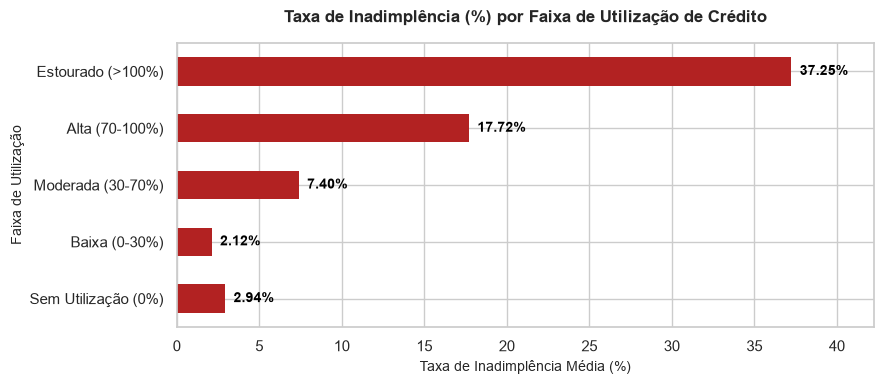

In [10]:
# Definimos os cortes com base nas práticas de mercado e comportamento da base
bins = [-1, 0.0, 0.3, 0.7, 1.0, np.inf]
rotulos = ['Sem Utilização (0%)', 'Baixa (0-30%)', 'Moderada (30-70%)', 'Alta (70-100%)', 'Estourado (>100%)']

df['Faixa_Utilizacao'] = pd.cut(df['RevolvingUtilizationOfUnsecuredLines'], bins=bins, labels=rotulos)

# Verificando a distribuição dos clientes dentro de cada faixa de utilização 
print("Distribuição dos clientes por Faixa de Utilização de Crédito:")
dist_utilizacao = pd.DataFrame({
    'Quantidade': df['Faixa_Utilizacao'].value_counts(),
    'Porcentagem (%)': (df['Faixa_Utilizacao'].value_counts(normalize=True) * 100).round(2)
})
display(dist_utilizacao)

# Gráfico da taxa de inadimplência por Faixa de Utilização de Crédito
plt.figure(figsize=(9, 4))
taxa_inad = df.groupby('Faixa_Utilizacao', observed=False)['SeriousDlqin2yrs'].mean() * 100

ax = taxa_inad.plot(kind='barh', color='firebrick', edgecolor='none')
plt.title('Taxa de Inadimplência (%) por Faixa de Utilização de Crédito', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Taxa de Inadimplência Média (%)', fontsize=10)
plt.ylabel('Faixa de Utilização', fontsize=10)

# Adicionando os valores nas barras
for p in ax.patches: # type: ignore
    width = p.get_width() # type: ignore
    ax.annotate(f'{width:.2f}%',
                (width + 0.5, p.get_y() + p.get_height() / 2.), # type: ignore
                ha='left', va='center',
                fontsize=10, color='black', fontweight='bold')

plt.xlim(0, max(taxa_inad.values) + 5)
plt.tight_layout()

# Salvar a imagem 
import os
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "taxa_inadim_faixa_utilizacao.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')

plt.show()

* **Perfil Majoritário Saudável:** Mais de 54% dos clientes concentram-se na faixa de utilização baixa (0% a 30%), indicando que a maior parte da base gerencia seus limites de forma conservadora e sustentável.

* **O Risco Oculto nas Pontas:** Cerca de 20% dos clientes encontram-se na faixa de utilização alta (70% a 100%) ou com o limite totalmente estourado (> 100%). No mercado de crédito, clientes que operam com estouro de limite costumam apresentar taxas de inadimplência muito acima da média devido ao sufoco crônico de liquidez.

A criação dessas faixas categóricas transforma uma relação contínua cheia de ruídos extremos em segmentos de risco comportamental bem delimitados, elevando a explicabilidade do modelo.

## Variáveis Derivadas e Comportamentais

Essas interações traduzem o comportamento financeiro, o histórico de adimplência e o comprometimento real de renda do tomador.

* **`Total_Atrasos`**: Soma de todas as ocorrências de atraso registradas nas três janelas de observação (30-59 dias, 60-89 dias e 90+ dias), unificando a reincidência de falhas do cliente.

* **`Historico_Atrasos_Flag`**: Marcação binária que isola diretamente se o cliente possui ou não qualquer histórico prévio de atraso (`0` para ficha limpa, `1` para quem já falhou ao menos uma vez), capturando o salto de risco inicial.

* **`Renda_Por_Dependente`**: Estima a renda familiar *per capita* dividindo a renda mensal pelo número de dependentes somado a um (incluindo o próprio titular e evitando divisões por zero), refletindo com mais justiça a capacidade de pagamento.

* **`Proporcao_Imobiliaria`**: Calcula o peso de empréstimos imobiliários em relação ao total de linhas de crédito abertas, capturando o compromisso com garantias de longo prazo.

* **`Utilizacao_Critica_Flag`**: Marcação binária que isola diretamente os clientes operando acima de 100% de utilização do rotativo, zona crítica mapeada em nossa EDA.

In [11]:
## Construção de Variáveis Derivadas e Comportamentais

# Criando cópia do dataframe 
df_feat = df.copy()

# Total de atrasos acumulados no histórico (tratando eventuais NaNs como 0 para a somatória)
cols_atraso = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse'
]
df_feat['Total_Atrasos'] = df_feat[cols_atraso].fillna(0).sum(axis=1)

# Flag binária indicando se o cliente já teve histórico de atraso (0 = Limpo, 1 = Com Histórico)
df_feat['Historico_Atrasos_Flag'] = (df_feat['Total_Atrasos'] > 0).astype(int)

# Renda per capita familiar (Renda / (Dependentes +1))
df_feat['Renda_Por_Dependente'] = df_feat['MonthlyIncome'] / (df_feat['NumberOfDependents'] + 1)

# Proporção de linhas imobiliárias sobre o total de créditos abertos (evitando divisão por 0)
df_feat['Proporcao_Imobiliaria'] = np.where(
    df_feat['NumberOfOpenCreditLinesAndLoans'] > 0,
    df_feat['NumberRealEstateLoansOrLines'] / df_feat['NumberOfOpenCreditLinesAndLoans'],
    0
)

# Flag indicadora de utilização crítica do limite (> 100%)
df_feat['Utilizacao_Critica_Flag'] = (df_feat['RevolvingUtilizationOfUnsecuredLines_clipped'] > 1.0).astype(int)

print("Novas variáveis criadas com sucesso!")
print(f"Dimensões atuais do DataFrame: {df_feat.shape}")

# Visualizando uma amostra das novas colunas
display(df_feat[['Total_Atrasos', 'Historico_Atrasos_Flag', 'Renda_Por_Dependente', 'Proporcao_Imobiliaria', 'Utilizacao_Critica_Flag']])

Novas variáveis criadas com sucesso!
Dimensões atuais do DataFrame: (149999, 20)


,Total_Atrasos,Historico_Atrasos_Flag,Renda_Por_Dependente,Proporcao_Imobiliaria,Utilizacao_Critica_Flag
0,2.0,1,3040.000000,0.461538,0
1,0.0,0,1300.000000,0.000000,0
2,2.0,1,3042.000000,0.000000,0
3,0.0,0,3300.000000,0.000000,0
4,1.0,1,63588.000000,0.142857,0
...,...,...,...,...,...
149994,0.0,0,2100.000000,0.250000,0
149995,0.0,0,1861.333333,0.250000,0
149996,0.0,0,5400.000000,0.055556,0
149997,0.0,0,5716.000000,0.000000,0


As novas variáveis traduzem o perfil de risco do tomador em métricas acionáveis e limpas para os algoritmos:

* **`Total_Atrasos`**: Consolida o histórico fragmentado de pontualidade em um único indicador cumulativo de propensão à falha.

* **`Historico_Atrasos_Flag`**: Isola com precisão a descontinuidade de comportamento entre clientes pontuais e aqueles que já registraram pelo menos um episódio de atraso.

* **`Renda_Por_Dependente`**: Melhora a precisão do comprometimento financeiro ao ponderar a renda bruta pelo encargo familiar.

* **`Proporcao_Imobiliaria`**: Revela o peso de ativos imobiliários na estrutura de endividamento do cliente.

* **`Utilizacao_Critica_Flag`**: Sinaliza explicitamente o limiar de estouro de limite, blindando o modelo com a principal alavanca de risco da carteira.

---
Com essas transformações aplicadas, o dataset ganha camadas fundamentais de inteligência de negócio e está pronto para a persistência final e transição rumo à modelagem preditiva.

In [12]:
## Visão de colunas disponíveis pós criação das features

print(f"Dimensões finais da base: {df_feat.shape}")
print("\nColunas disponíveis no dataset final:")
for col in df_feat.columns:
    print(f"- {col}")

Dimensões finais da base: (149999, 20)

Colunas disponíveis no dataset final:
- SeriousDlqin2yrs
- RevolvingUtilizationOfUnsecuredLines
- age
- NumberOfTime30-59DaysPastDueNotWorse
- DebtRatio
- MonthlyIncome
- NumberOfOpenCreditLinesAndLoans
- NumberOfTimes90DaysLate
- NumberRealEstateLoansOrLines
- NumberOfTime60-89DaysPastDueNotWorse
- NumberOfDependents
- Renda_Ausente_Flag
- RevolvingUtilizationOfUnsecuredLines_clipped
- DebtRatio_clipped
- Faixa_Utilizacao
- Total_Atrasos
- Historico_Atrasos_Flag
- Renda_Por_Dependente
- Proporcao_Imobiliaria
- Utilizacao_Critica_Flag


In [13]:
## Persistência da base enriquecida

## Remoção das colunas originais que foram substituídas pelas versões tratadas (_clipped)
## evita redundância e limpa o dataset para a modelagem 
colunas_para_removar =[
    'RevolvingUtilizationOfUnsecuredLines',
    'DebtRatio'
]
df_feat = df_feat.drop(columns=colunas_para_removar, errors='ignore')

# Salvando a base com a feature engineering no SQLite
conexao = sqlite3.connect("../data/credit_scoring.db")
df_feat.to_sql("credito_feature_engineered", conexao, if_exists="replace", index=False)

print(f"Base com engenharia de recursos salva com sucesso na tabela 'credito_feature_engineered'!")
print(f"Dimensões finais da base: {df_feat.shape}")
print("\nColunas disponíveis no dataset final:")
for col in df_feat.columns:
    print(f"- {col}")

Base com engenharia de recursos salva com sucesso na tabela 'credito_feature_engineered'!
Dimensões finais da base: (149999, 18)

Colunas disponíveis no dataset final:
- SeriousDlqin2yrs
- age
- NumberOfTime30-59DaysPastDueNotWorse
- MonthlyIncome
- NumberOfOpenCreditLinesAndLoans
- NumberOfTimes90DaysLate
- NumberRealEstateLoansOrLines
- NumberOfTime60-89DaysPastDueNotWorse
- NumberOfDependents
- Renda_Ausente_Flag
- RevolvingUtilizationOfUnsecuredLines_clipped
- DebtRatio_clipped
- Faixa_Utilizacao
- Total_Atrasos
- Historico_Atrasos_Flag
- Renda_Por_Dependente
- Proporcao_Imobiliaria
- Utilizacao_Critica_Flag
